# Task 4 — NLP Sentiment Classification on Customer Reviews (TF-IDF)

**Goal:** build a text classifier that labels reviews as *positive* or *negative*.

**Pipeline:** load data → clean & tokenize (lowercase, HTML/punctuation removal, stopwords, lemmatization) → `TfidfVectorizer(max_features=5000)` → train `MultinomialNB` and `LogisticRegression` → benchmark → `predict_sentiment()` helper.

**A note on data.** The provided starter file `sentiment_reviews.csv` has only **10 rows** (5 positive, 4 negative, 1 neutral) — enough to demo the pipeline but far too small to train or benchmark a model honestly. So:
1. The starter CSV is loaded, inspected and used as a small *out-of-domain sanity check* (product reviews).
2. The model is trained and benchmarked on NLTK's **movie_reviews** corpus (2,000 labelled reviews), which the task explicitly allows ("product or movie review records").

## 1. Setup

In [1]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4", "movie_reviews"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords, movie_reviews
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 2. Load the data

### 2a. Starter file (`sentiment_reviews.csv`)

In [2]:
STARTER_PATH = "sentiment_reviews.csv"   # adjust if the file lives elsewhere
starter = pd.read_csv(STARTER_PATH)
print(starter.shape)
print(starter["sentiment"].value_counts())
starter

(10, 3)
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


The starter set contains one `neutral` row. The task is *binary* (positive vs. negative), so that row is dropped for evaluation.

### 2b. Training corpus (NLTK movie reviews)

In [3]:
docs = [(movie_reviews.raw(fid), cat) for cat in movie_reviews.categories()
        for fid in movie_reviews.fileids(cat)]
df = pd.DataFrame(docs, columns=["review_text", "sentiment"])
print(df.shape)
print(df["sentiment"].value_counts())
print("\nMedian review length (words):", int(df["review_text"].str.split().str.len().median()))
df.sample(3, random_state=1)

(2000, 2)
sentiment
neg    1000
pos    1000
Name: count, dtype: int64

Median review length (words): 696


,review_text,sentiment
674,steve martin is one of the funniest men alive ...,neg
1699,very few people would be unaware of beavis & b...,pos
1282,"ok , let's get one thing straight right away :...",pos


## 3. Text preprocessing

Steps: strip HTML tags → lowercase → keep letters only (removes punctuation/digits) → tokenize → remove stopwords → lemmatize.

**Design choice:** NLTK's default stopword list contains negations (`not`, `no`, `nor`, `don't`, …). For sentiment these words flip meaning ("not good"), so I **keep them** and only drop the rest. Because punctuation is stripped, contractions like `don't` become `don` + `t`; to avoid losing that signal, common contractions are expanded to `not` first.

In [4]:
LEMMATIZER = WordNetLemmatizer()
NEGATIONS = {"no", "nor", "not", "never"}
STOP = set(stopwords.words("english")) - NEGATIONS - {"t"}  # keep negations

CONTRACTIONS = [
    (r"won't", "will not"), (r"can't", "can not"), (r"n't", " not"),
    (r"'re", " are"), (r"'ve", " have"), (r"'ll", " will"), (r"'m", " am"),
]

def preprocess(text: str) -> str:
    """Raw review -> cleaned, lemmatized string ready for TF-IDF."""
    text = re.sub(r"<[^>]+>", " ", str(text))          # HTML tags
    text = text.lower()                                 # lowercase
    for pat, rep in CONTRACTIONS:                       # expand contractions
        text = re.sub(pat, rep, text)
    text = re.sub(r"[^a-z\s]", " ", text)             # punctuation, digits
    tokens = text.split()                               # tokenize
    tokens = [t for t in tokens if t not in STOP and len(t) > 1]
    # lemmatize as noun, then as verb (so "stopped"->"stop", "movies"->"movie")
    tokens = [LEMMATIZER.lemmatize(LEMMATIZER.lemmatize(t, "n"), "v") for t in tokens]
    return " ".join(tokens)

examples = [
    "<p>The product quality is exceptional, exceeded all my expectations!</p>",
    "Terrible customer service and the item arrived completely damaged.",
    "I didn't like it. It wasn't worth the money.",
]
for e in examples:
    print(e, "\n  ->", preprocess(e), "\n")

<p>The product quality is exceptional, exceeded all my expectations!</p> 
  -> product quality exceptional exceed expectation 

Terrible customer service and the item arrived completely damaged. 
  -> terrible customer service item arrive completely damage 

I didn't like it. It wasn't worth the money. 
  -> not like not worth money 



In [5]:
df["clean_text"] = df["review_text"].apply(preprocess)
starter["clean_text"] = starter["review_text"].apply(preprocess)
df[["review_text", "clean_text"]].head(2).assign(review_text=lambda d: d.review_text.str[:150])

,review_text,clean_text
0,"plot : two teen couples go to a church party ,...",plot two teen couple go church party drink dri...
1,the happy bastard's quick movie review \ndamn ...,happy bastard quick movie review damn bug get ...


## 4. Train / test split and TF-IDF features

80/20 stratified split. The vectorizer is wrapped in a `Pipeline` with the classifier so it is **fit on training data only** (no leakage into the test set). I use `max_features=5000` as specified, with unigrams + bigrams (e.g. "not good" becomes a feature) and `min_df=2` to drop one-off tokens.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["sentiment"],
    test_size=0.2, stratify=df["sentiment"], random_state=RANDOM_STATE)
print("train:", len(X_train), " test:", len(X_test))

def make_tfidf():
    return TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# Peek at the feature matrix
_vec = make_tfidf()
_X = _vec.fit_transform(X_train)
print("TF-IDF matrix:", _X.shape, "| sparsity: %.2f%% zeros" % (100 * (1 - _X.nnz / np.prod(_X.shape))))
print("Sample features:", list(_vec.get_feature_names_out()[1000:1012]))

train: 1600  test: 400
TF-IDF matrix: (1600, 5000) | sparsity: 95.44% zeros
Sample features: ['dark city', 'darkness', 'darn', 'darren', 'darth', 'dash', 'data', 'date', 'daughter', 'dave', 'david', 'davis']


## 5. Train the models

In [7]:
models = {
    "MultinomialNB": Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB(alpha=0.5))]),
    "LogisticRegression": Pipeline([("tfidf", make_tfidf()),
                                    ("clf", LogisticRegression(C=10, max_iter=1000, random_state=RANDOM_STATE))]),
}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"trained {name}")

trained MultinomialNB
trained LogisticRegression


## 6. Accuracy benchmarks

In [8]:
results, preds = {}, {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, pipe in models.items():
    preds[name] = pipe.predict(X_test)
    cv_scores = cross_val_score(make_pipe := Pipeline(pipe.steps), df["clean_text"], df["sentiment"], cv=cv)
    results[name] = {
        "Test accuracy": accuracy_score(y_test, preds[name]),
        "5-fold CV mean": cv_scores.mean(),
        "5-fold CV std": cv_scores.std(),
    }
    print("=" * 60, f"\n{name}\n", "=" * 60)
    print(classification_report(y_test, preds[name], digits=3))

summary = pd.DataFrame(results).T.round(4)
summary

MultinomialNB
              precision    recall  f1-score   support

         neg      0.807     0.815     0.811       200
         pos      0.813     0.805     0.809       200

    accuracy                          0.810       400
   macro avg      0.810     0.810     0.810       400
weighted avg      0.810     0.810     0.810       400

LogisticRegression
              precision    recall  f1-score   support

         neg      0.874     0.835     0.854       200
         pos      0.842     0.880     0.861       200

    accuracy                          0.858       400
   macro avg      0.858     0.857     0.857       400
weighted avg      0.858     0.858     0.857       400



,Test accuracy,5-fold CV mean,5-fold CV std
MultinomialNB,0.8100,0.823,0.0093
LogisticRegression,0.8575,0.867,0.0112


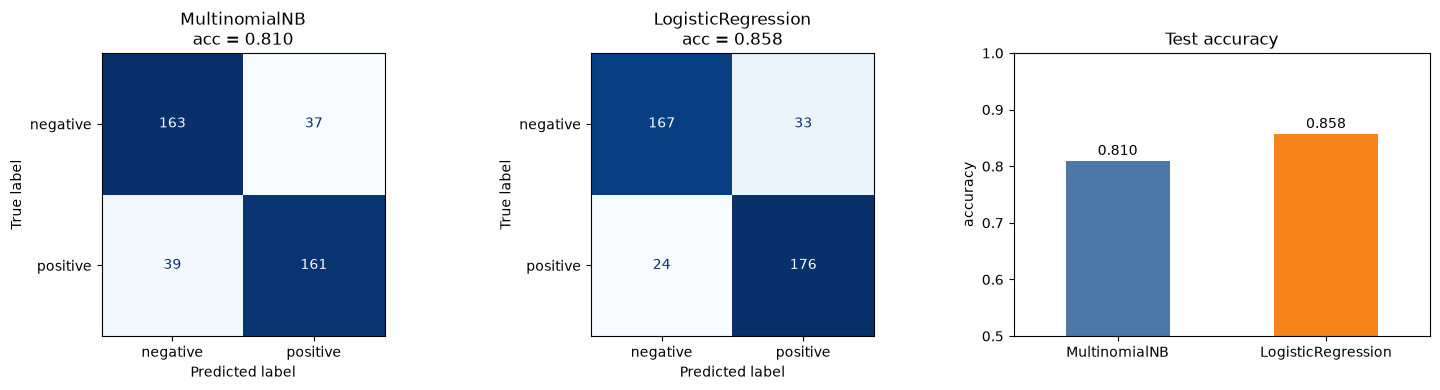

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes[:2], preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p, labels=["neg", "pos"]),
                           display_labels=["negative", "positive"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nacc = {accuracy_score(y_test, p):.3f}")

summary["Test accuracy"].plot.bar(ax=axes[2], color=["#4C78A8", "#F58518"], rot=0)
axes[2].set_ylim(0.5, 1); axes[2].set_title("Test accuracy"); axes[2].set_ylabel("accuracy")
for i, v in enumerate(summary["Test accuracy"]):
    axes[2].text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

### Which words drive the predictions? (Logistic Regression coefficients)

In [10]:
lr = models["LogisticRegression"]
vocab = lr.named_steps["tfidf"].get_feature_names_out()
coefs = lr.named_steps["clf"].coef_[0]          # classes_ = ['neg', 'pos']
order = np.argsort(coefs)
top_neg = [(vocab[i], round(coefs[i], 2)) for i in order[:12]]
top_pos = [(vocab[i], round(coefs[i], 2)) for i in order[::-1][:12]]
print("Most NEGATIVE:", top_neg)
print("\nMost POSITIVE:", top_pos)

Most NEGATIVE: [('bad', np.float64(-6.21)), ('bore', np.float64(-4.75)), ('worst', np.float64(-4.58)), ('waste', np.float64(-4.5)), ('suppose', np.float64(-4.46)), ('nothing', np.float64(-4.46)), ('ridiculous', np.float64(-3.68)), ('plot', np.float64(-3.59)), ('awful', np.float64(-3.49)), ('unfortunately', np.float64(-3.38)), ('attempt', np.float64(-3.32)), ('mess', np.float64(-3.18))]

Most POSITIVE: [('great', np.float64(3.75)), ('well', np.float64(3.69)), ('hilarious', np.float64(3.62)), ('fun', np.float64(3.38)), ('overall', np.float64(3.36)), ('performance', np.float64(3.28)), ('excellent', np.float64(3.19)), ('perfect', np.float64(3.16)), ('terrific', np.float64(3.05)), ('also', np.float64(2.99)), ('job', np.float64(2.97)), ('memorable', np.float64(2.87))]


### Sanity check on the provided starter reviews (out-of-domain)
These are *product* reviews, while the model was trained on *movie* reviews, so a drop in accuracy is expected — vocabulary like "damaged", "adapter cable" or "durable build" is rare in film reviews. With only 9 binary rows this is a smoke test, not a benchmark.

In [11]:
starter_bin = starter[starter["sentiment"].isin(["positive", "negative"])].copy()
label_map = {"positive": "pos", "negative": "neg"}
y_true = starter_bin["sentiment"].map(label_map)

rows = {}
for name, pipe in models.items():
    p = pipe.predict(starter_bin["clean_text"])
    starter_bin[f"pred_{name}"] = p
    rows[name] = accuracy_score(y_true, p)
print({k: f"{v:.0%}" for k, v in rows.items()}, f"(n={len(starter_bin)})")
starter_bin[["review_text", "sentiment", "pred_MultinomialNB", "pred_LogisticRegression"]]

{'MultinomialNB': '78%', 'LogisticRegression': '67%'} (n=9)


,review_text,sentiment,pred_MultinomialNB,pred_LogisticRegression
0,"The product quality is exceptional, exceeded a...",positive,pos,neg
1,Terrible customer service and the item arrived...,negative,neg,neg
3,"Absolutely love this! Easy to setup, robust, a...",positive,pos,pos
4,Stopped working after two days. Extremely disa...,negative,pos,pos
5,Customer support helped resolve my setup quest...,positive,neg,neg
6,Delivery was slow and package was missing one ...,negative,neg,neg
7,Clean interface and intuitive controls. Highly...,positive,pos,pos
8,"Not worth the money, plenty of better alternat...",negative,neg,neg
9,Great value and durable build. Would definitel...,positive,pos,pos


## 7. Interactive test helper — `predict_sentiment()`

Final model: both pipelines are refit on **all** 2,000 reviews (benchmarks above were measured before this refit, on held-out data) and the helper returns the label plus a confidence score.

In [12]:
final_models = {name: Pipeline(pipe.steps).fit(df["clean_text"], df["sentiment"])
                for name, pipe in models.items()}
LABELS = {"pos": "positive", "neg": "negative"}

def predict_sentiment(text: str, model: str = "LogisticRegression", verbose: bool = True):
    """Classify a raw review string.

    model: "LogisticRegression" or "MultinomialNB".
    Returns (label, confidence) where confidence is the predicted-class probability.
    """
    if not isinstance(text, str) or not preprocess(text).strip():
        raise ValueError("Please provide a review containing at least one meaningful word.")
    pipe = final_models[model]
    proba = pipe.predict_proba([preprocess(text)])[0]
    idx = int(np.argmax(proba))
    label, conf = LABELS[pipe.classes_[idx]], float(proba[idx])
    if verbose:
        print(f"[{model}] {label.upper():8s} ({conf:.0%})  <-  {text}")
    return label, conf

tests = [
    "Absolutely loved this film, brilliant acting and a gripping story!",
    "What a waste of time. Boring plot and terrible acting.",
    "The product quality is exceptional, exceeded all my expectations!",
    "Stopped working after two days. Extremely disappointed.",
    "It was not good at all.",
    "Not bad, actually quite enjoyable.",
]
for t in tests:
    for m in final_models:
        predict_sentiment(t, m)
    print()

[MultinomialNB] POSITIVE (72%)  <-  Absolutely loved this film, brilliant acting and a gripping story!
[LogisticRegression] POSITIVE (81%)  <-  Absolutely loved this film, brilliant acting and a gripping story!

[MultinomialNB] NEGATIVE (94%)  <-  What a waste of time. Boring plot and terrible acting.
[LogisticRegression] NEGATIVE (100%)  <-  What a waste of time. Boring plot and terrible acting.

[MultinomialNB] POSITIVE (60%)  <-  The product quality is exceptional, exceeded all my expectations!
[LogisticRegression] NEGATIVE (68%)  <-  The product quality is exceptional, exceeded all my expectations!

[MultinomialNB] POSITIVE (52%)  <-  Stopped working after two days. Extremely disappointed.
[LogisticRegression] POSITIVE (71%)  <-  Stopped working after two days. Extremely disappointed.

[MultinomialNB] NEGATIVE (67%)  <-  It was not good at all.
[LogisticRegression] NEGATIVE (75%)  <-  It was not good at all.

[MultinomialNB] NEGATIVE (61%)  <-  Not bad, actually quite enjoyable.
[L

In [13]:
def interactive_test(model: str = "LogisticRegression"):
    """Type reviews and get live predictions. Press Enter on an empty line to quit."""
    print(f"Live sentiment tester ({model}). Empty line to exit.")
    while True:
        text = input("Review > ").strip()
        if not text:
            break
        try:
            predict_sentiment(text, model)
        except ValueError as e:
            print("  ", e)

# Uncomment to try your own phrases:
# interactive_test()

## 8. Findings & limitations

- **Results (held-out test set, n=400):** Logistic Regression **85.8%** accuracy vs. Multinomial Naive Bayes **81.0%**; 5-fold CV agrees (86.7% vs. 82.6%), so the split isn't a fluke. LR wins as expected: it learns discriminative weights, while NB assumes feature independence. Top-weighted words (*bad, bore, worst, waste* / *great, hilarious, excellent*) are sensible.
- **Domain shift:** on the 9 binary starter *product* reviews, accuracy drops to 78% (NB) and 67% (LR), and LR is no longer ahead. With n=9 that is noise-level evidence, but it does show the movie-trained vocabulary doesn't transfer well (e.g. "Stopped working after two days. Extremely disappointed." is misclassified: "working"/"days" lean positive in film reviews). For production use, train on in-domain product reviews; the pipeline is dataset-agnostic, so swapping in a larger product-review CSV with `review_text` / `sentiment` columns only requires changing §2.
- **Known weak spot:** "Not bad, actually quite enjoyable." is predicted negative. Bigrams help with "not good" but not with negated-negative phrases.
- **Limits of bag-of-words:** TF-IDF can't fully handle sarcasm, long-range negation or mixed sentiment. Bigrams help with phrases like "not good", but not everything.
- **Neutral class:** the starter file has a `neutral` label; extending to 3-class is a small change (drop the binary filter and use multi-class LR / NB).
- **Possible extensions:** hyperparameter search (`GridSearchCV` over `C`, `alpha`, `ngram_range`), spaCy lemmatization with POS tags, and error analysis on misclassified reviews.